# Handling Imbalanced Data with Oversampling

Lab Assignment 7 - training a classifier on the imbalanced Pima Indians Diabetes dataset, then balancing the training data with Random Oversampling and SMOTE and comparing the results before and after.

### Libraries used

Everything is standard apart from imbalanced-learn, which provides the oversampling methods:

pip install pandas numpy matplotlib scikit-learn imbalanced-learn

In [2]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import RandomOverSampler, SMOTE

## 1. Load the dataset

In [3]:
cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv'
df = pd.read_csv(url, names=cols)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.shape

(768, 9)

## 2. Class distribution

Outcome 0 = no diabetes, 1 = diabetes.

In [5]:
df['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


In [6]:
df['Outcome'].value_counts(normalize=True).round(3)

,proportion
Outcome,
0,0.651
1,0.349


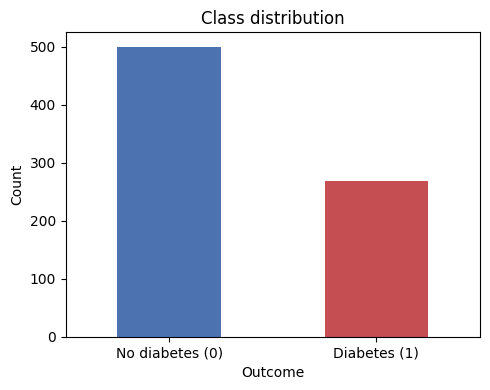

In [7]:
plt.figure(figsize=(5, 4))
df['Outcome'].value_counts().plot(kind='bar', color=['#4c72b0', '#c44e52'])
plt.xticks([0, 1], ['No diabetes (0)', 'Diabetes (1)'], rotation=0)
plt.ylabel('Count')
plt.title('Class distribution')
plt.tight_layout()
plt.show()

Around 65% of the samples are non-diabetic and only 35% are diabetic, so the dataset is imbalanced towards class 0.

## 3. Preprocessing

There are no NaN values, but some columns have zeros that are not physically possible (a Glucose or BMI of 0). These are really missing values, so they get replaced with the median of the column.

In [8]:
print("NaN values:", df.isnull().sum().sum())

zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
(df[zero_cols] == 0).sum()

NaN values: 0


,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


In [9]:
df[zero_cols] = df[zero_cols].replace(0, np.nan)
df[zero_cols] = df[zero_cols].fillna(df[zero_cols].median())
(df[zero_cols] == 0).sum()

,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0


## 4. Train/test split

80/20 split, stratified so the test set has the same imbalance as the original data. Oversampling is only applied to the training set later - the test set is left untouched so it still reflects the real class distribution.

In [10]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)
y_train.value_counts()

(614, 8) (154, 8)


,count
Outcome,
0,400
1,214


## 5 & 6. Classifier on the imbalanced data

Logistic Regression is used for all three runs so the only thing that changes is the training data.

In [11]:
def evaluate(y_pred):
    return {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    }

In [12]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred_before = model.predict(X_test_scaled)

print(classification_report(y_test, y_pred_before))

              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



## 7. Oversampling the training set

**Random Oversampling** just duplicates random samples from the minority class until both classes are the same size.

**SMOTE** creates new synthetic minority samples by interpolating between a minority sample and one of its nearest minority neighbours.

In [13]:
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(X_train_scaled, y_train)
y_train_ros.value_counts()

,count
Outcome,
0,400
1,400


In [14]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
y_train_smote.value_counts()

,count
Outcome,
0,400
1,400


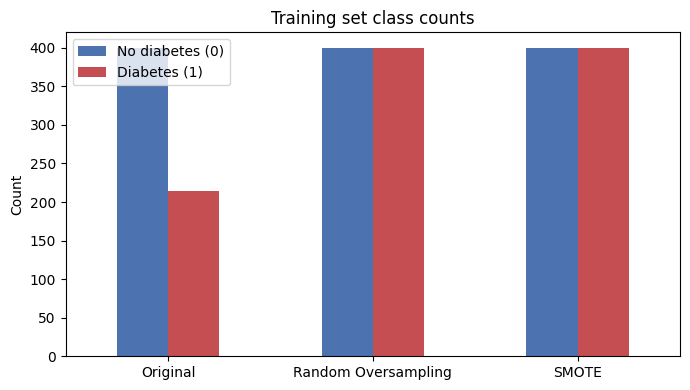

In [15]:
counts = pd.DataFrame({
    'Original': y_train.value_counts(),
    'Random Oversampling': y_train_ros.value_counts(),
    'SMOTE': y_train_smote.value_counts()
}).T

counts.plot(kind='bar', figsize=(7, 4), color=['#4c72b0', '#c44e52'])
plt.ylabel('Count')
plt.title('Training set class counts')
plt.xticks(rotation=0)
plt.legend(['No diabetes (0)', 'Diabetes (1)'])
plt.tight_layout()
plt.show()

## 8. Classifier on the balanced data

In [16]:
model_ros = LogisticRegression(max_iter=1000)
model_ros.fit(X_train_ros, y_train_ros)
y_pred_ros = model_ros.predict(X_test_scaled)

print(classification_report(y_test, y_pred_ros))

              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



In [17]:
model_smote = LogisticRegression(max_iter=1000)
model_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = model_smote.predict(X_test_scaled)

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.80      0.74      0.77       100
           1       0.58      0.67      0.62        54

    accuracy                           0.71       154
   macro avg       0.69      0.70      0.70       154
weighted avg       0.73      0.71      0.72       154



## 9. Before vs after oversampling

Precision, recall and F1 are for the diabetic class (1), since that is the minority class we care about.

In [18]:
results = pd.DataFrame({
    'Before oversampling': evaluate(y_pred_before),
    'Random Oversampling': evaluate(y_pred_ros),
    'SMOTE': evaluate(y_pred_smote)
}).T
results.round(4)

,Accuracy,Precision,Recall,F1 Score
Before oversampling,0.7078,0.6000,0.5000,0.5455
Random Oversampling,0.7338,0.6032,0.7037,0.6496
SMOTE,0.7143,0.5806,0.6667,0.6207


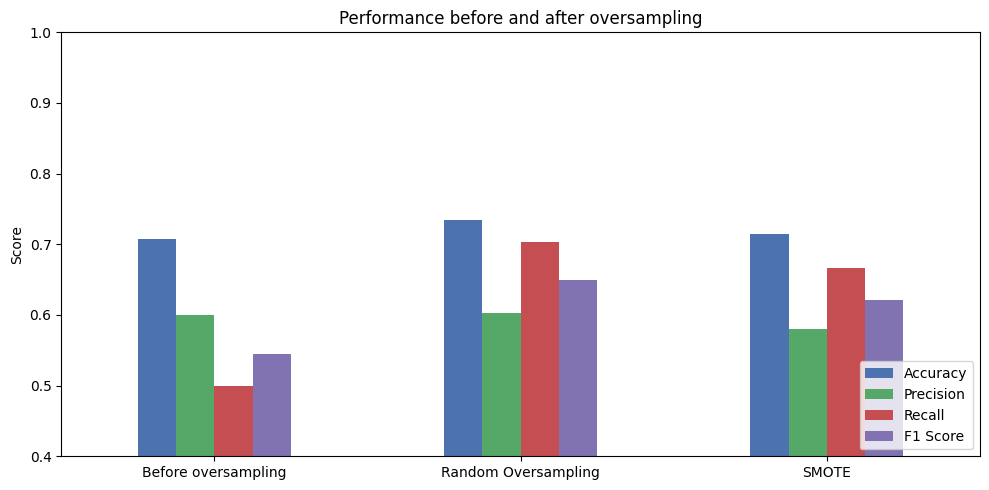

In [19]:
results.plot(kind='bar', figsize=(10, 5), color=['#4c72b0', '#55a868', '#c44e52', '#8172b2'])
plt.ylabel('Score')
plt.title('Performance before and after oversampling')
plt.ylim(0.4, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

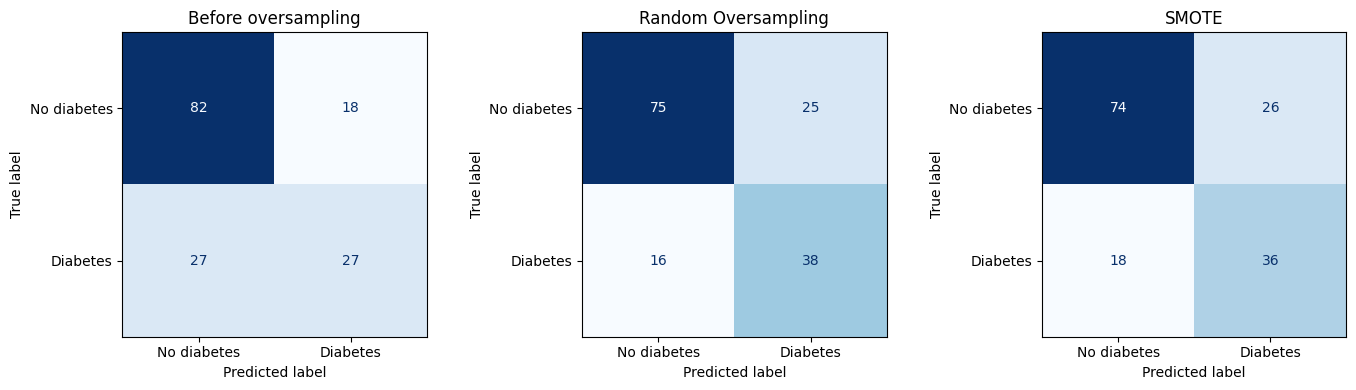

In [20]:
preds = {'Before oversampling': y_pred_before, 'Random Oversampling': y_pred_ros, 'SMOTE': y_pred_smote}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['No diabetes', 'Diabetes']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 10. Observations

On the original imbalanced data the model is biased towards the majority class. Accuracy looks fine, but a lot of diabetic patients in the test set get predicted as non-diabetic, which shows up as a low recall for class 1 and in the bottom left cell of the first confusion matrix.

After oversampling, both classes have the same number of training samples, so the model stops favouring class 0. Recall for the diabetic class goes up clearly with both Random Oversampling and SMOTE, meaning far fewer diabetic patients are missed. The trade-off is a few more false positives, so precision drops a little and overall accuracy stays about the same or goes down slightly.

Random Oversampling and SMOTE give fairly similar results here. SMOTE has the advantage of not just copying the same rows again, which lowers the risk of overfitting to duplicated samples.

## Conclusion

In this experiment a Logistic Regression classifier was trained on the imbalanced Pima Indians Diabetes dataset, and then retrained after balancing the training set with Random Oversampling and SMOTE. The results show that accuracy alone is misleading for imbalanced data - the model trained on the original data had a reasonable accuracy but missed many of the minority class cases.

Oversampling improved recall and F1 score for the diabetic class, at the cost of a small drop in precision. For a medical problem like diabetes detection, missing a positive case is usually worse than a false alarm, so the oversampled models are the better choice. It is also important that oversampling is done only on the training set, so the test set still represents the real world class distribution and the evaluation stays fair.